In [ ]:
import sys,os
from datetime import datetime
from pathlib import Path
import json
import torch # 张量、自动求导等
import torch.nn as nn # 网络层，Conv1D、LSTM等
import torch.nn.functional as F # 函数层， ReLU、cross_entropy等
from torchinfo import summary
from torch.utils.data import DataLoader,TensorDataset
import time
import gc
from sklearn.metrics import roc_auc_score

root = Path(r"C:\Users\hank\Desktop\Research Reproduction\dianxian\self")
chb_data_path = Path(r"D:\data\dianxian\channal_select\chb03")

if str(root) not in sys.path:
    sys.path.append(str(root))

import tools as t

embeddings = root / 'embeddings'
weight = root / 'weight'
Fp1_F7 = embeddings / 'Fp1-F7'
Fp2_F8 = embeddings / 'Fp2-F8'
T7_P7 = embeddings / 'T7-P7'
T8_P8 = embeddings / 'T8-P8'
P7_O1 = embeddings / 'P7-O1'
P8_O2 = embeddings / 'P8-O2'

out_channals = 32
batch = 32
elec = 6
window_length = 10 * 256
window_overlap = 5 * 256
elec_names = ['Fp1-F7', 'Fp2-F8', 'T7-P7', 'T8-P8', 'P7-O1', 'P8-O2']

In [ ]:
print(torch.cuda.is_available(),torch.cuda.get_device_name(0))

encoder

pytorch中channal/filters在前

padding = 'same' -> padding = kernel_size - 1,output_padding = stride - 1

-> conv_same,conv_transpose_same


In [ ]:
class ConvPaddingSame(nn.Module):
    def __init__(self):
        super().__init__()

    def Conv1d(self,in_c,out_c,kernel_size,stride=1,groups=1,bias=False):
        padding = kernel_size // 2
        return nn.Conv1d(in_c,out_c,kernel_size,stride=stride,padding=padding,groups=groups,bias=bias)

    def ConvTranspose1d(self,in_c,out_c,kernel_size,stride=1,groups=1,bias=False):
        padding = kernel_size // 2
        output_padding = stride - 1
        return nn.ConvTranspose1d(in_c,out_c,kernel_size,stride=stride,padding=padding,groups=groups,bias=bias,output_padding=output_padding)

In [ ]:
class AutoEncoder(nn.Module):
    def __init__(self,in_channals=1,out_channals=out_channals,kernel_size=3,n_layers=3):
        super().__init__()
        self.n_layers = n_layers
        self.kernel_size = kernel_size
        self.in_channals = in_channals
        self.out_channals = out_channals
        self.cps = ConvPaddingSame()
        self.encoder = self.build_encoder()
        self.decoder = self.build_decoder()

    def depthwise_sep_conv1d(self,in_channals,out_channals,kernel_size):
        return nn.Sequential(
            # 深度卷积变长度
            self.cps.Conv1d(
                in_channals,in_channals,kernel_size,
                stride=2,bias=True,groups=in_channals
            ),
            nn.BatchNorm1d(in_channals),
            nn.ReLU(),
            # 逐点卷积变通道
            self.cps.Conv1d(in_channals,out_channals,kernel_size=1,stride=1),
            nn.BatchNorm1d(out_channals),
            nn.ReLU(),
        )

    # 编码器
    def build_encoder(self):
        n = max(self.n_layers-2,0)
        layers = [self.depthwise_sep_conv1d(self.out_channals,self.out_channals,self.kernel_size) for _ in range(n)]
        return nn.Sequential(
            # 1 -> out_channals
            self.depthwise_sep_conv1d(self.in_channals,self.out_channals,self.kernel_size),
            *layers,
            # 取平均值
            nn.AvgPool1d(self.kernel_size,stride=2,padding=self.kernel_size//2)
        )

    # 解码器
    def build_decoder(self):
        # output_padding = stride + 2padding - kernel_size
        layers = [self.cps.ConvTranspose1d(self.out_channals,self.out_channals,self.kernel_size,stride=2) for _ in range(self.n_layers-1)]
        return nn.Sequential(
            *layers,
            self.cps.ConvTranspose1d(self.out_channals,self.in_channals,self.kernel_size,stride=2)
        )

    def forward(self,x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

model = AutoEncoder()
summary(model,input_size=(32,1,1000))

common convlution（Wang2021）

输入格式：(N,C,L)

In [ ]:
class CommonConv1d(nn.Module):
    def __init__(self):
        super().__init__()
        self.cps = ConvPaddingSame()
        self.cl = [1,2,4,8,16,32]
        self.model = self.build_model()

    def cell_layer(self,in_c,out_c):
        return nn.Sequential(
            self.cps.Conv1d(in_c,out_c,kernel_size=3,stride=1),
            nn.BatchNorm1d(out_c),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2,stride=2)
        )

    # channals = 1 -> [2,4,8,16,32]
    def build_model(self,):
        m = [self.cell_layer(self.cl[i-1],self.cl[i]) for i in range(1,len(self.cl))]
        return nn.Sequential(*m)

    def forward(self,x):
        return self.model(x)

model = CommonConv1d()
summary(model,input_size=(32,1,2000))


时序注意力(pytorch中Linear默认对最后一个维度进行计算，不改变其他维度形状)

输入：（N,L,C）

softmax：使指定维度的数据归一化，所有数据之和为1，不改变维度，体现此消彼长的关系

torch.sum：默认不保留求和的维度

In [ ]:
class TemporalAttention(nn.Module):
    def __init__(self,channals):
        super().__init__()
        self.fc = nn.Linear(channals,1)

    def attention(self,x):
        scores = self.fc(x) # (N,L,C) -> (N,L,1)
        weights = F.softmax(scores,dim=1) # (N,L,1)
        atten = weights * x # (N,L,C)
        return weights,atten

    def forward(self,x):
        return self.attention(x)

通道注意力

channals压缩之后起码要在2以上才有注意力的必要

In [ ]:
class ChannalAttention(nn.Module):
    def __init__(self,channals):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(channals,channals // 2),
            nn.LayerNorm(channals // 2),
            nn.ReLU(),
            nn.Linear(channals // 2,channals),
            nn.Sigmoid()
        )

    def attention(self,x):
        pooled = x.mean(dim=1) # (N,C) 压缩时间序列但原序列不变
        weights = self.fc(pooled).unsqueeze(dim=1) # (N,1,C)
        atten = weights * x # (N,L,C)
        return weights,atten

    def forward(self,x):
        return self.attention(x)

Bi-LSTM Classify

输入格式：(N,L,C)

pytorch的LSTM中的循环连接层的recurrent_dropout需要自己实现，其次拼接方式默认为直接拼接

LSTM -> out,(h_n,c_n)；out包括每一样本的每一步的数据，(h_n,c_n)只包含每一层的最后状态

In [ ]:
class BILSTMClassify(nn.Module):
    def __init__(self,input_size=out_channals,hidden_size=10,num_layers=1,dropout=0,temporal_attention=False,channal_attention=False): # input_size是encoder输出的channals
        super().__init__()
        self.BI_LSTM = nn.LSTM(
            input_size = input_size,
            hidden_size = hidden_size, # 隐藏状态维度
            num_layers = num_layers, # 隐藏层层数
            batch_first = True,
            bidirectional = True,  # 开启双向
        )
        self.fc = nn.Linear(2*hidden_size,1)
        self.dropout = nn.Dropout(dropout)
        self.temporal_attention = temporal_attention
        self.channal_attention = channal_attention
        # 时序注意力
        if self.temporal_attention:
            self.temp_atten = TemporalAttention(2*hidden_size)
        # 通道注意力
        if self.channal_attention:
            self.chan_atten = ChannalAttention(2*hidden_size)

    def forward(self,x):
        x,_ = self.BI_LSTM(x)
        if self.channal_attention:
            _,x = self.chan_atten(x)
        if self.temporal_attention:
            _,x = self.temp_atten(x)
            out = x.sum(dim=1)
        else:
            out = x[:,-1,:]
        out = self.dropout(out)
        return self.fc(out)

model = BILSTMClassify()
summary(model,input_size=(batch,62,32))

encoder：(N,C,L) -> (N,C,L)

BI-LSTM Classify：(N,L,C) -> (N,)

encoder + BI-LSTM Classify

In [ ]:
class EncoderBILSTMClassify(nn.Module):
    def __init__(self,weight_path,in_channals=1,out_channals=out_channals,kernel_size=3,n_layers=3,input_size=out_channals,hidden_size=10,num_layers=1,dropout=0,temporal_attention=False,channal_attention=False):
        super().__init__()
        self.ae = AutoEncoder(in_channals,out_channals,kernel_size,n_layers)
        self.ae.load_state_dict(torch.load(weight_path)) # 加载权重
        self.encoder = self.ae.build_encoder()
        for param in self.encoder.parameters():
            param.requires_grad = False # 冻结权重
        self.classify = BILSTMClassify(input_size,hidden_size,num_layers,dropout,temporal_attention,channal_attention)

    def forward(self,x):
        x = self.encoder(x)
        x = x.permute(0,2,1)
        return self.classify(x)


conv + BI-LSTM Classfy

In [ ]:
class ConvBILSTMClassify(nn.Module):
    def __init__(self,input_size=out_channals,hidden_size=10,num_layers=1,dropout=0,temporal_attention=False,channal_attention=False):
        super().__init__()
        self.common_conv = CommonConv1d()
        self.classify = BILSTMClassify(out_channals,hidden_size,num_layers,dropout,temporal_attention,channal_attention)

    def forward(self,x):
        x = self.common_conv(x)
        x = x.permute(0,2,1)
        return self.classify(x)

model = ConvBILSTMClassify()
summary(model,(32,1,2000))

chb22 LOOCV 数据预处理
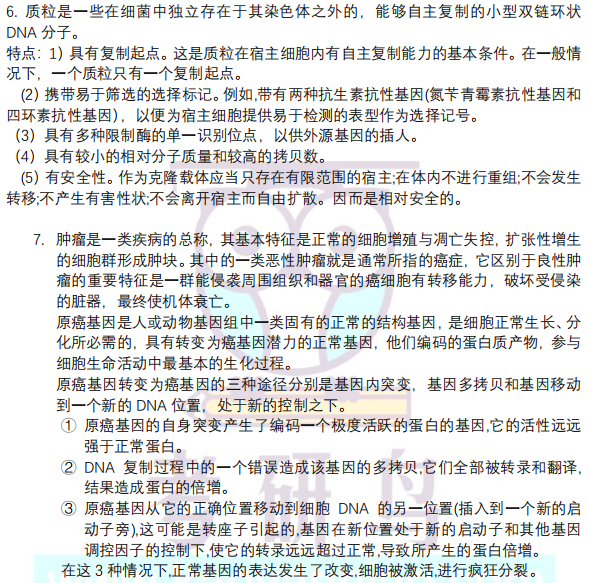

In [ ]:
# # 预处理
# windows,meta = t.preprocess(r"D:\data\dianxian\wang2021\chb22",SPH=2*60,SOP=30*60,interictal_thr=2*60*60,window_length=4,window_overlap=2,elec_names=elec_names) # 获取窗口与元数据

数据集划分

In [ ]:
encoder_val = 0.1
classfy_val = 0.2

dataset[

    elec[fold]{"train"}

]

In [ ]:
# def train_val_test(elec_names,meta,windows,seed,val=(encoder_val,classfy_val),method="LOOCV"):
#     dataset = [] # dataset[elec[fold{"train"}]]
#     for elec in elec_names:
#         data_set = t.split_train_test(meta[elec],seed=seed,val=val,method=method)
#         elec_list = []
#         for fold in range(len(data_set)):
#             encoder_train_idx = data_set[fold]["auto_encoder_idx"]
#             encoder_val_idx = data_set[fold]["auto_encoder_val_idx"]
#             train_idx = data_set[fold]["train_idx"]
#             val_idx = data_set[fold]["val_idx"]
#             test_idx = data_set[fold]["test_idx"]
#             wins_and_label = {}
#
#             # 原始窗口 -> 升维 -> 张量 float32
#             # 自编码器
#             wins_and_label["encoder_train_wins"] = torch.tensor(windows[elec][encoder_train_idx][:,None,:],dtype=torch.float32)
#             wins_and_label["encoder_val_wins"] = torch.tensor(windows[elec][encoder_val_idx][:,None,:],dtype=torch.float32)
#             # 训练集和标签
#             wins_and_label["train_wins"] = torch.tensor(windows[elec][train_idx][:,None,:],dtype=torch.float32)
#             wins_and_label["y_train"] = torch.tensor(meta[elec].iloc[train_idx].label.to_numpy(),dtype=torch.float32).unsqueeze(1)
#             # 验证集和标签
#             wins_and_label["val_wins"] = torch.tensor(windows[elec][val_idx][:,None,:],dtype=torch.float32)
#             wins_and_label["y_val"] = torch.tensor(meta[elec].iloc[val_idx].label.to_numpy(),dtype=torch.float32).unsqueeze(1)
#             # 测试集和标签
#             wins_and_label["test_wins"] = torch.tensor(windows[elec][test_idx][:,None,:],dtype=torch.float32)
#             wins_and_label["y_test"] = torch.tensor(meta[elec].iloc[test_idx].label.to_numpy(),dtype=torch.float32).unsqueeze(1)
#
#             # 按elec_names顺序归类到dataset的该elec下
#             elec_list.append(wins_and_label)
#
#         dataset.append(elec_list)
#     return dataset

In [ ]:
# # 划分数据集(自编码器不需要测试集，但需要避免数据泄露，仍一起划分)
#
# # data_set中是每一折窗口的下标
# data_set = t.split_train_test(meta["T7-P7"],seed=0,val=(0.2,0.2),method="LOOCV")
#
# print(data_set[1].keys())
#
# # 自编码器
# # 训练集
# encoder_train_f1_idx = data_set[1]["auto_encoder_idx"]
# encoder_train_f1_wins = windows["T7-P7"][encoder_train_f1_idx]
# # 验证集
# encoder_val_f1_idx = data_set[1]["auto_encoder_val_idx"]
# encoder_val_f1_wins = windows["T7-P7"][encoder_val_f1_idx]
#
# # 训练集
# train_f1_idx = data_set[1]["train_idx"]
# train_f1_wins = windows["T7-P7"][train_f1_idx]
# y_train = meta["T7-P7"].iloc[train_f1_idx].label.to_numpy() # 标签
# # 验证集
# val_f1_idx = data_set[1]["val_idx"]
# val_f1_wins = windows["T7-P7"][val_f1_idx]
# y_val = meta["T7-P7"].iloc[val_f1_idx].label.to_numpy()
# # 测试集
# test_f1_idx = data_set[1]["test_idx"]
# test_f1_wins = windows["T7-P7"][test_f1_idx]
# y_test = meta["T7-P7"].iloc[test_f1_idx].label.to_numpy()
#
# print(encoder_train_f1_wins.shape)
# print(encoder_val_f1_wins.shape)
# print(train_f1_wins.shape)
# print(y_train.shape)
# print(val_f1_wins.shape)
# print(test_f1_wins.shape)

增加维度 -> (N,1,L)

In [ ]:
# encoder_train_f1_data = encoder_train_f1_wins[:,None,:]
# encoder_val_f1_data = encoder_val_f1_wins[:,None,:]
# train_f1_data = train_f1_wins[:,None,:]
# val_f1_data = val_f1_wins[:,None,:]
# test_f1_data = test_f1_wins[:,None,:]
#
# print(type(encoder_train_f1_data))
# print(type(train_f1_data))
# print(encoder_train_f1_wins.shape)
# print(encoder_val_f1_wins.shape)
# print(train_f1_wins.shape)
# print(y_train.shape)
# print(val_f1_wins.shape)
# print(test_f1_wins.shape)

回收内存

In [ ]:
# import gc
# del windows,meta,train_f1_wins,val_f1_wins,test_f1_wins,encoder_train_f1_wins,encoder_val_f1_wins
# gc.collect()

训练

tensordataset：负责打包数据

DataLoader：加载每一批数据

In [ ]:
# print(type(encoder_train_f1_data))
# print(type(encoder_val_f1_data))

In [ ]:
# # 1.数据准备
# # numpy.ndarray -> torch.tensor
# ae_train_data = torch.tensor(encoder_train_f1_data,dtype=torch.float32)
# ae_val_data = torch.tensor(encoder_val_f1_data,dtype=torch.float32)
#
# ae_train_loader = DataLoader(TensorDataset(ae_train_data),batch_size=32,shuffle=True)
# ae_val_loader = DataLoader(TensorDataset(ae_val_data),batch_size=32,shuffle=False)

In [ ]:
# # 2.模型初始化
# autoencoder = AutoEncoder().to('cuda')
# loss_function = nn.MSELoss()
# optimizer = torch.optim.Adam(autoencoder.parameters(),lr=0.001)
#
# best_val_loss = float('inf') # 初始化为无穷大
# patience = 5
# patience_counter = 0
# epochs = 10
#
# # 3.循环训练
# for epoch in range(epochs): # 每一轮包括训练和验证阶段
#     start_time = time.time()
#
#     # 3.1 训练
#     autoencoder.train()
#     train_loss = 0
#     for (x,) in ae_train_loader:      # loader返回元组
#         x = x.to('cuda')              # 将数据放到gpu上训练
#         optimizer.zero_grad()         # 梯度清零
#         out = autoencoder(x)          # 前向传播
#         loss = loss_function(out, x)  # 计算损失
#         loss.backward()               # 反向传播
#         optimizer.step()              # 梯度更新
#         train_loss += loss.item()
#
#     avg_train_loss = train_loss / len(ae_train_loader)
#
#     # 3.2 验证
#     autoencoder.eval()
#     val_loss = 0
#     with torch.no_grad(): # 验证不需要算梯度
#         for (x,) in ae_val_loader:
#             x = x.to('cuda')
#             out = autoencoder(x)
#             loss = loss_function(out,x)
#             val_loss += loss.item()
#
#     avg_val_loss = val_loss / len(ae_val_loader) # 平均每批误差
#
#     # 3.3 日志打印
#     end_time = time.time()
#     print(f"Epoch [{epoch+1:02d}/{epochs}] | "
#           f"Train Loss: {avg_train_loss:.2e} | "
#           f"Val Loss: {avg_val_loss:.2e} | "
#           f"Time: {end_time - start_time:.1f}s")
#
#     # 3.4 早停判断与模型保存
#     if avg_val_loss < best_val_loss:
#         best_val_loss = avg_val_loss
#         patience_counter = 0
#         torch.save(autoencoder.state_dict(),str(root / "weight" / "autoencoder.pth")) # 权重保存
#     else:
#         patience_counter += 1
#         if patience_counter == patience:
#             print(f"早停触发：loss已经连续{patience}轮没有下降了")
#             break

Conv + BI-LSTM Classify

y：必须是二维的输入，如（N,1）

In [ ]:
# # 数据准备
# if isinstance(train_f1_data,torch.tensor):
#     print('数据类型已转成torch.tensor')
# else:
#     train_f1_data = torch.tensor(train_f1_data,dtype=torch.float32)
#     val_f1_data = torch.tensor(val_f1_data,dtype=torch.float32)
#     test_f1_data = torch.tensor(test_f1_data,dtype=torch.float32)
#     y_train = torch.tensor(y_train,dtype=torch.float32).unsqueeze(1)
#     y_val = torch.tensor(y_val,dtype=torch.float32).unsqueeze(1)
#     y_test = torch.tensor(y_test,dtype=torch.float32).unsqueeze(1)
#
# # 打包DataLoader
# train_f1_loader = DataLoader(TensorDataset(train_f1_data,y_train),batch_size=32,shuffle=True)
# val_f1_loader = DataLoader(TensorDataset(val_f1_data,y_val),batch_size=32,shuffle=False)
# test_f1_loader = DataLoader(TensorDataset(test_f1_data,y_test),batch_size=32,shuffle=False)

In [ ]:
# # 模型
# conv_bi_lstm = ConvBILSTMClassify(channal_attention=channal_attention,temporal_attention=temporal_attention).to("cuda")
# optimizer = torch.optim.Adam(conv_bi_lstm.parameters(),lr=1e-4)
# loss_function = nn.BCEWithLogitsLoss()
#
# patience_counter = 0
# best_val_auc = 0
# patience = 20
# epochs = 50
# best_val_loss = float('inf')
#
# for epoch in range(epochs):
#     start_time = time.time()
#     train_loss = 0
#     val_loss = 0
#
#     # 训练
#     conv_bi_lstm.train()
#     for (x,y) in train_f1_loader:
#         x,y = x.to("cuda"),y.to("cuda")
#         optimizer.zero_grad()
#         out = conv_bi_lstm(x)
#         loss = loss_function(out,y)
#         loss.backward()
#         optimizer.step()
#         train_loss += loss.item()
#     # 训练集平均损失
#     avg_train_loss = train_loss / len(train_f1_loader)
#
#     # 验证
#     conv_bi_lstm.eval()
#     val_probs = []
#     val_targets = []
#     with torch.no_grad():
#         for (x,y) in val_f1_loader:
#             x,y = x.to("cuda"),y.to("cuda")
#             out = conv_bi_lstm(x)
#             loss = loss_function(out,y)
#             val_loss += loss.item()
#
#             # 收集预测概率和真实标签，用于算 AUC
#             probs = torch.sigmoid(out) # 模型输出是 logits，要转成概率
#             # sklearn只接收一维的numpy，而numpy必须在cpu上运行
#             val_probs.extend(probs.cpu().numpy().flatten())
#             val_targets.extend(y.cpu().numpy().flatten())
#
#     # 测试集平均损失
#     avg_val_loss = val_loss / len(val_f1_loader)
#
#     # 计算验证集 AUC
#     val_auc = roc_auc_score(val_targets, val_probs)
#
#     # 打印日志
#     end_time = time.time()
#     print(f"Epoch [{epoch+1:02d}/{epochs}] | "
#           f"Train Loss: {avg_train_loss:.2e} | "
#           f"Val Loss: {avg_val_loss:.2e} | "
#           f"Val AUC: {val_auc:.4f} | "
#           f"Time: {end_time - start_time:.1f}s")
#
#     if avg_val_loss < best_val_loss:
#         best_val_loss = avg_val_loss
#         patience_counter = 0
#         torch.save(conv_bi_lstm.state_dict(),str(root / "weight" / "conv_bi_lstm.pth")) # 保存最优权重
#
#     # if val_auc > best_val_auc:
#     #     best_val_auc = val_auc
#     #     patience_counter = 0
#     #     torch.save(conv_bi_lstm.state_dict(),str(root / "weight" / "conv_bi_lstm.pth"))
#     else:
#         patience_counter += 1
#         if  patience_counter == patience:
#             print(f"早停触发：loss已经连续{patience}轮没有下降了")
#             break

训练

In [ ]:
# 预处理
windows,meta = t.preprocess(r"D:\data\dianxian\wang2021\chb22",SPH=2*60,SOP=30*60,interictal_thr=2*60*60,window_length=4,window_overlap=2,elec_names=elec_names) # 获取窗口与元数据

In [ ]:
def train_val_test(elec_names, meta, windows, seed, val=(encoder_val, classfy_val), method="LOOCV"):
    dataset = []
    for elec in elec_names:
        data_set = t.split_train_test(meta[elec], seed=seed, val=val, method=method)
        elec_list = []
        for fold in range(len(data_set)):
            encoder_train_idx = data_set[fold]["auto_encoder_idx"]
            encoder_val_idx = data_set[fold]["auto_encoder_val_idx"]
            train_idx = data_set[fold]["train_idx"]
            val_idx = data_set[fold]["val_idx"]
            test_idx = data_set[fold]["test_idx"]
            wins_and_label = {}

            wins_and_label["encoder_train_wins"] = torch.tensor(windows[elec][encoder_train_idx][:, None, :], dtype=torch.float32)
            wins_and_label["encoder_val_wins"] = torch.tensor(windows[elec][encoder_val_idx][:, None, :], dtype=torch.float32)
            wins_and_label["train_wins"] = torch.tensor(windows[elec][train_idx][:, None, :], dtype=torch.float32)
            wins_and_label["y_train"] = torch.tensor(meta[elec].iloc[train_idx].label.to_numpy(), dtype=torch.float32).unsqueeze(1)
            wins_and_label["val_wins"] = torch.tensor(windows[elec][val_idx][:, None, :], dtype=torch.float32)
            wins_and_label["y_val"] = torch.tensor(meta[elec].iloc[val_idx].label.to_numpy(), dtype=torch.float32).unsqueeze(1)
            wins_and_label["test_wins"] = torch.tensor(windows[elec][test_idx][:, None, :], dtype=torch.float32)
            wins_and_label["y_test"] = torch.tensor(meta[elec].iloc[test_idx].label.to_numpy(), dtype=torch.float32).unsqueeze(1)

            elec_list.append(wins_and_label)

        dataset.append(elec_list)
    return dataset


def train_elec_model(model, optimizer, loss_function, dataset, elec_idx, device='cuda', patience=5, epochs=30):
    model.to(device)
    now = datetime.now().strftime("%y%m_%d_%H%M%S")
    fold_paths = []
    fold_logs = {}


    for fold in range(len(dataset[elec_idx])):
        train_dataloader = DataLoader(TensorDataset(dataset[elec_idx][fold]["train_wins"], dataset[elec_idx][fold]["y_train"]), batch_size=batch_size, shuffle=True)
        val_dataloader = DataLoader(TensorDataset(dataset[elec_idx][fold]["val_wins"], dataset[elec_idx][fold]["y_val"]), batch_size=batch_size, shuffle=False)

        patience_counter = 0
        best_val_loss = float("inf")
        best_model_state = None
        fold_logs[f"fold_{fold + 1}"] = {"epochs": []}

        for epoch in range(epochs):
            start_time = time.time()
            train_loss = 0
            val_loss = 0

            model.train()
            for (x, y) in train_dataloader:
                x, y = x.to("cuda"), y.to("cuda")
                optimizer.zero_grad()
                out = model(x)
                loss = loss_function(out, y)
                loss.backward()
                optimizer.step()
                train_loss += loss.item()

            avg_train_loss = train_loss / len(train_dataloader)

            model.eval()
            with torch.no_grad():
                val_targets = []
                val_probs = []
                for (x, y) in val_dataloader:
                    x, y = x.to("cuda"), y.to("cuda")
                    out = model(x)
                    loss = loss_function(out, y)
                    val_loss += loss.item()
                    probs = torch.sigmoid(out)
                    val_probs.extend(probs.cpu().numpy().flatten())
                    val_targets.extend(y.cpu().numpy().flatten())

            avg_val_loss = val_loss / len(val_dataloader)
            val_auc = roc_auc_score(val_targets, val_probs)

            end_time = time.time()

            fold_logs[f"fold_{fold + 1}"]["epochs"].append({
                "epoch": epoch + 1,
                "train_loss": round(avg_train_loss, 6),
                "val_loss": round(avg_val_loss, 6),
                "val_auc": round(val_auc, 4),
                "time": round(end_time - start_time, 2)
            })

            print(f"Epoch [{epoch+1:02d}/{epochs}] | "
                  f"Train Loss: {avg_train_loss:.2e} | "
                  f"Val Loss: {avg_val_loss:.2e} | "
                  f"Val AUC: {val_auc:.4f} | "
                  f"Time: {end_time - start_time:.1f}s")

            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                patience_counter = 0
                best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            else:
                patience_counter += 1
                if patience_counter == patience:
                    print("Early Stopping")
                    fold_logs[f"fold_{fold + 1}"]["early_stop_epoch"] = epoch + 1
                    break

        if best_model_state is not None:
            path = root / "weight" / f"{now}_{elec_names[elec_idx]}_fold{fold+1}.pth"
            fold_paths.append(path)
            torch.save(best_model_state, path)
            fold_logs[f"fold_{fold + 1}"]["weight_path"] = path
            fold_logs[f"fold_{fold + 1}"]["best_val_loss"] = round(best_val_loss, 6)

    return fold_paths,fold_logs


In [ ]:
channal_attention = False
temporal_attention = False

In [ ]:
models = []
for i in range(len(elec_names)):
    model = ConvBILSTMClassify(channal_attention=channal_attention, temporal_attention=temporal_attention,dropout=dropout)
    models.append(model)

dataset = train_val_test(elec_names, meta, windows, seed=seed, val=(0.1, 0.1))

now = datetime.now().strftime("%y%m_%d_%H%M%S")
log_dir = root / "train_log"
combined_manifest = {
    "config": {
        "learning_rate": learning_rate,
        "weight_decay": weight_decay,
        "batch_size": batch_size,
        "dropout": dropout,
        "patience": patience,
        "epochs": epochs,
        "channal_attention": channal_attention,
        "temporal_attention": temporal_attention,
        "hidden_size": hidden_size
    },
    "weights": [],  # 全局只留一份权重列表
    "logs": {}  # 按电极名分别记录详细日志
}
for i, model in enumerate(models):
    print(f"正在训练model：{elec_names[i]}")
    optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate,weight_decay=weight_decay)
    loss_function = nn.BCEWithLogitsLoss()
    fold_paths,fold_logs = train_elec_model(model, optimizer, loss_function, dataset, elec_idx=i, device='cuda', patience=patience, epochs=epochs)

    combined_manifest["weights"].extend(fold_paths)  # 把这一电极的所有权重路径拼进去
    combined_manifest["logs"][elec_names[i]] = fold_logs  # 按电极名存入日志

    del model, optimizer, loss_function
    torch.cuda.empty_cache()
    gc.collect()
    print(f"[清理] {elec_names[i]} 训练完成，显存已释放。")

json_path = log_dir / f"{now}_weights_manifest.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(combined_manifest, f, indent=4, ensure_ascii=False, default=str)

验证

In [ ]:
import re
import math

In [ ]:
def parse_date(date):
    """
    date:如 261028
    """
    date = str(date)
    if len(date) != 6:
        print("请输入正确格式的日期，如'261028'")
        return None
    year_month = date[:4]
    day = date[-2:]
    ym_d = year_month + "_" + day
    return ym_d

# def match_date(date,filenames:list):
#     matched = []
#     for filename in filenames:
#         m = re.search(date,filename)
#         if date in filename:
#             matched.append(filename)
#     return matched

def match_config(config:dict,query:dict):
    for k,v in query.items():
        if k not in config:
            print(f"config中没有参数:{k}")
            return False
        config_v = config[k]
        # 只有数字才比较
        # bool是一种特殊的int，因此要额外排除
        if isinstance(config_v, (int, float)) and not isinstance(config_v, bool) \
           and isinstance(v, (int, float)) and not isinstance(v, bool):
            if math.isclose(config_v,v,rel_tol=1e-4):
                continue
            else:
                return False
        else:
            if config_v != v:
                return False
    return True

# **kwargs：将k：v打包成字典
def find_weights():
    """
    {"file_path": ,"config": ,"mtime":} reverse = True 降序
    """
    pass

def test_elec_model():
    pass


In [ ]:
from sklearn.metrics import roc_auc_score

conv_bi_lstm = ConvBILSTMClassify(channal_attention=channal_attention,temporal_attention=temporal_attention).to("cuda")
conv_bi_lstm.load_state_dict(torch.load(str(root / "weight" / "conv_bi_lstm.pth")))

targets = []
preds = []

conv_bi_lstm.eval()
with torch.no_grad():
    for (x,y) in test_f1_loader:
        x,y = x.to("cuda"),y.to("cuda")
        pred = F.sigmoid(conv_bi_lstm(x))
        targets.extend(y.cpu().numpy().flatten())
        preds.extend(pred.cpu().numpy().flatten())

auc = roc_auc_score(targets,preds)
print(f"AUC:{auc:.4f}")



In [ ]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

def evaluate_classification(y_true, y_prob, threshold=0.5):
    """
    计算二分类模型的各种评估指标
    :param y_true: 真实标签 (numpy array 或 list, 形状 1D)
    :param y_prob: 预测概率 (numpy array 或 list, 形状 1D)
    :param threshold: 判定阳性的阈值，默认 0.5
    :return: 包含各项指标的字典
    """
    # 确保输入是一维数组
    y_true = np.array(y_true).flatten()
    y_prob = np.array(y_prob).flatten()

    # 根据阈值将概率转为 0/1 预测标签
    y_pred = (y_prob >= threshold).astype(int)

    # 计算混淆矩阵
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    # 计算各项指标
    auc = roc_auc_score(y_true, y_prob)
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)

    # 敏感度 (Sensitivity) = 召回率 (Recall) = TP / (TP + FN)
    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    # 特异度 (Specificity) = TN / (TN + FP)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    f1 = f1_score(y_true, y_pred, zero_division=0)
    bal_acc = (sensitivity + specificity) / 2  # 平衡准确率

    # 打印结果
    print("=" * 40)
    print(f"📊 分类评估指标 (Threshold = {threshold})")
    print("=" * 40)
    print(f"测试集样本数: {len(y_true)} (阳性 {tp+fn} / 阴性 {tn+fp})")
    print(f"AUC-ROC     : {auc:.4f}")
    print(f"Accuracy    : {acc:.4f}")
    print(f"Balanced Acc: {bal_acc:.4f}")
    print(f"Sensitivity : {sensitivity:.4f} (Recall)")
    print(f"Specificity : {specificity:.4f}")
    print(f"Precision   : {precision:.4f}")
    print(f"F1-Score    : {f1:.4f}")
    print("-" * 40)
    print(f"混淆矩阵: TP={tp}, FP={fp}, TN={tn}, FN={fn}")
    print("=" * 40)

    return {
        "auc": auc, "accuracy": acc, "balanced_acc": bal_acc,
        "sensitivity": sensitivity, "specificity": specificity,
        "precision": precision, "f1": f1,
        "tp": tp, "fp": fp, "tn": tn, "fn": fn
    }

In [ ]:
evaluate_classification(targets,preds)